# Croatia IMF Country Report 25/329

## 0. Local setup and report configuration

In [1]:
# Work from the folder where the Jupyter kernel is started.
from pathlib import Path
BASE_DIR = Path.cwd()
print("Working directory:", BASE_DIR)

Working directory: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis


In [2]:
import os
import re
import json
import time
import math
import pathlib
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pypdf import PdfReader
import tiktoken
from pydantic import BaseModel, Field, ValidationError

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
PDF_PATH = BASE_DIR / 'Croatia_IMF_Country_Report_2025.pdf'
OUT = BASE_DIR / 'croatia_outputs'
OUT.mkdir(parents=True, exist_ok=True)

print("Project folder:", BASE_DIR)
print("PDF location:", PDF_PATH)
print("Output folder:", OUT)

Project folder: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis
PDF location: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\Croatia_IMF_Country_Report_2025.pdf
Output folder: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs


In [4]:
if PDF_PATH.is_file():
    print("SUCCESS: IMF Croatia PDF found!")
    print("File name:", PDF_PATH.name)
    print("File size:", round(PDF_PATH.stat().st_size / (1024 * 1024), 2), "MB")
else:
    print("ERROR: PDF file not found.")
    print("Expected location:", PDF_PATH)

    print("\nAvailable PDF files:")
    for file in BASE_DIR.glob("*.pdf"):
        print("-", file.name)

    raise FileNotFoundError(
        "Place the IMF Croatia PDF in the current project directory."
    )

SUCCESS: IMF Croatia PDF found!
File name: Croatia_IMF_Country_Report_2025.pdf
File size: 9.03 MB


In [5]:
reader = PdfReader(str(PDF_PATH))
total_pages = len(reader.pages)

print("PDF loaded successfully!")
print("Total pages:", total_pages)

# Check the first 10 pages
sample_text = ""

for i in range(min(10, total_pages)):
    page_text = reader.pages[i].extract_text() or ""

    print(f"Page {i+1}: {len(page_text)} characters")

    sample_text += "\n" + page_text

# Check whether Croatia appears in extracted text
if "CROATIA" in sample_text.upper():
    print("\nSUCCESS: Croatia IMF report verified!")
else:
    print("\nWARNING: Croatia not found in extracted text.")
    print("The PDF may contain image-based pages.")

print("\nExtracted text preview:")
print(sample_text[:1500])

PDF loaded successfully!
Total pages: 74
Page 1: 0 characters
Page 2: 1564 characters
Page 3: 2954 characters
Page 4: 3987 characters
Page 5: 305 characters
Page 6: 3715 characters
Page 7: 3211 characters
Page 8: 2819 characters
Page 9: 1110 characters
Page 10: 1713 characters

SUCCESS: Croatia IMF report verified!

Extracted text preview:


 
© 2025 International Monetary Fund 
IMF Country Report No. 25/329 
REPUBLIC OF CROATIA 
2025 ARTICLE IV CONSULTATION—PRESS RELEASE 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions 
with members, usually every year. In the context of the 2025 Article IV consultation with 
the Republic of Croatia, the following documents have been released and are included in 
this package: 
 
• A Press Release. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s 
consideration on a lapse-of-time basis following discussions that ended on 
November 4, 2025, with the officials of

In [6]:
# OpenRouter uses the OpenAI-compatible Python client.
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(BASE_DIR / '.env')
API_KEY = os.getenv('OPENROUTER_API_KEY')
if not API_KEY:
    raise RuntimeError('Set OPENROUTER_API_KEY in the local .env file.')

MODEL_A = "google/gemini-3.7-flash"
MODEL_B = "google/gemini-3.5-flash-lite"

client = OpenAI(
    api_key=API_KEY,
    base_url='https://openrouter.ai/api/v1',
    timeout=120.0
)

print('OpenRouter client configured successfully!')
print('Primary model:', MODEL_A)
print('Evaluation model:', MODEL_B)

OpenRouter client configured successfully!
Primary model: google/gemini-3.7-flash
Evaluation model: google/gemini-3.5-flash-lite


In [7]:
def save_json(name, obj):
    output_path = OUT / name

    output_path.write_text(
        json.dumps(
            obj,
            ensure_ascii=False,
            indent=2,
            default=str
        ),
        encoding="utf-8"
    )

    print("Saved:", output_path)

    return output_path

print("JSON output function ready!")

JSON output function ready!


## 1. PDF ingestion, cleaning and overlapping token chunks

In [8]:
# Load PDF and define cleaning function
reader = PdfReader(str(PDF_PATH))

def clean_page(s):
    s = s.replace('\u00ad', '')
    s = s.replace('\ufb01', 'fi')
    s = s.replace('\ufb02', 'fl')

    # Fix words broken by line endings
    s = re.sub(r'(?<=\w)-\n(?=\w)', '', s)

    # Join single line breaks
    s = re.sub(r'(?<!\n)\n(?!\n)', ' ', s)

    # Remove excessive spaces
    s = re.sub(r'[ \t]+', ' ', s)

    # Normalize paragraph breaks
    return re.sub(r'\n{3,}', '\n\n', s).strip()

print("PDF loaded successfully!")
print("Total pages:", len(reader.pages))
print("Text cleaning function ready!")

PDF loaded successfully!
Total pages: 74
Text cleaning function ready!


In [9]:
# Extract raw text

raw_pages = [
    p.extract_text(extraction_mode='layout') or ''
    for p in reader.pages
]

print("Total extracted pages:", len(raw_pages))

total_characters = sum(len(p) for p in raw_pages)

print("Total characters:", total_characters)

# Display extraction statistics
page_stats = pd.DataFrame({
    'PDF_Page': range(1, len(raw_pages) + 1),
    'Characters': [len(p) for p in raw_pages]
})

display(page_stats.head(10))

Rotated text discovered. Output will be incomplete.
Rotated text discovered. Output will be incomplete.
Rotated text discovered. Output will be incomplete.
Rotated text discovered. Output will be incomplete.
Rotated text discovered. Output will be incomplete.


Total extracted pages: 74
Total characters: 672235


,PDF_Page,Characters
0,1,0
1,2,2833
2,3,3516
3,4,4169
4,5,405
5,6,15846
6,7,6051
7,8,5703
8,9,2745
9,10,3593


In [10]:
# Detect repeated headers and footers

linesets = []

for p in raw_pages:

    lines = [
        x.strip()
        for x in p.splitlines()
        if x.strip()
    ]

    linesets.append(lines[:3] + lines[-3:])

counts = collections.Counter(
    x
    for ls in linesets
    for x in set(ls)
)

threshold = max(
    4,
    math.ceil(len(raw_pages) * 0.20)
)

repeated = {
    x
    for x, c in counts.items()
    if c >= threshold and len(x) < 90
}

print("Repeated headers/footers detected:", len(repeated))

for line in sorted(repeated):
    print("-", line)

Repeated headers/footers detected: 1
- REPUBLIC OF CROATIA


In [11]:
# Clean extracted PDF pages

cleaned = []

for p in raw_pages:

    lines = p.splitlines()

    # Remove empty lines at beginning
    while lines and not lines[0].strip():
        lines.pop(0)

    # Remove empty lines at end
    while lines and not lines[-1].strip():
        lines.pop()

    # Identify page-edge lines
    edge_indices = (
        list(range(min(3, len(lines))))
        +
        list(range(max(0, len(lines)-3), len(lines)))
    )

    # Remove repeated headers and footers
    for ix in set(edge_indices):
        if lines[ix].strip() in repeated:
            lines[ix] = ''

    # Apply text cleaning
    cleaned.append(
        clean_page('\n'.join(lines))
    )

print("Pages cleaned:", len(cleaned))

print("\nCleaned text preview:")
print(cleaned[1][:1000])

Pages cleaned: 74

Cleaned text preview:
IMF Country Report No. 25/329

 2025 ARTICLE IV CONSULTATION—PRESS RELEASE December 2025 AND STAFF REPORT

 Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions with members, usually every year. In the context of the 2025 Article IV consultation with the Republic of Croatia, the following documents have been released and are included in this package:

 • A Press Release.

 • The Staff Report prepared by a staff team of the IMF for the Executive Board’s consideration on a lapse-of-time basis following discussions that ended on November 4, 2025, with the officials of the Republic of Croatia on economic developments and policies. Based on information available at the time of these discussions, the staff report was completed on November 20, 2025.

 • An Informational Annex prepared by the IMF staff.

 The documents listed below have been or will be separately released.

 Selected Issues

 The IMF’s transparency po

In [12]:
# Save cleaned report

cleaned_report = '\n\n'.join(
    f'[PDF PAGE {i+1}]\n{p}'
    for i, p in enumerate(cleaned)
)

output_file = OUT / 'cleaned_report.txt'

output_file.write_text(
    cleaned_report,
    encoding='utf-8'
)

print("Cleaned report saved successfully!")
print("File:", output_file)
print("Characters:", len(cleaned_report))

Cleaned report saved successfully!
File: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\cleaned_report.txt
Characters: 151074


In [13]:
# Configure tokenization

enc = tiktoken.get_encoding('cl100k_base')

CHUNK_SIZE = 450
OVERLAP = 50

STEP_SIZE = CHUNK_SIZE - OVERLAP

print("Tokenizer initialized!")
print("Chunk size:", CHUNK_SIZE)
print("Overlap:", OVERLAP)
print("Step size:", STEP_SIZE)

Tokenizer initialized!
Chunk size: 450
Overlap: 50
Step size: 400


In [14]:
# Create token-aware chunks

chunks = []

for page_no, page_text in enumerate(cleaned, 1):

    ids = enc.encode(page_text)

    for start in range(0, len(ids), STEP_SIZE):

        part = ids[start:start + CHUNK_SIZE]

        if not part:
            break

        chunks.append({
            'id': len(chunks),
            'pdf_page': page_no,
            'start_token': start,
            'text': enc.decode(part)
        })

        if start + CHUNK_SIZE >= len(ids):
            break

print("Total chunks created:", len(chunks))

Total chunks created: 139


In [15]:
# Save chunks to Google Drive

save_json(
    'chunks.json',
    chunks
)

print("Chunk JSON saved successfully!")

Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\chunks.json
Chunk JSON saved successfully!


In [16]:
# Validate extraction and chunking

total_tokens = sum(
    len(enc.encode(p))
    for p in cleaned
)

chunk_lengths = [
    len(enc.encode(c['text']))
    for c in chunks
]

print("PDF Processing Summary")
print("-" * 40)

print("PDF pages:", len(raw_pages))
print("Total tokens:", f"{total_tokens:,}")
print("Total chunks:", len(chunks))

print(
    "Average chunk length:",
    round(np.mean(chunk_lengths), 2)
)

print(
    "Maximum chunk length:",
    max(chunk_lengths)
)

print(
    "Minimum chunk length:",
    min(chunk_lengths)
)

print("\nFirst chunk preview:")
print(chunks[0]['text'][:500])

print("\nNote: PDF page numbers may differ")
print("from printed IMF report page numbers.")

PDF Processing Summary
----------------------------------------
PDF pages: 74
Total tokens: 41,224
Total chunks: 139
Average chunk length: 320.31
Maximum chunk length: 450
Minimum chunk length: 43

First chunk preview:
IMF Country Report No. 25/329

 2025 ARTICLE IV CONSULTATION—PRESS RELEASE December 2025 AND STAFF REPORT

 Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions with members, usually every year. In the context of the 2025 Article IV consultation with the Republic of Croatia, the following documents have been released and are included in this package:

 • A Press Release.

 • The Staff Report prepared by a staff team of the IMF for the Executive Board’s conside

Note: PDF page numbers may differ
from printed IMF report page numbers.


## 2. Dense embeddings and local FAISS retrieval

In [17]:
# Import RAG libraries

from sentence_transformers import SentenceTransformer
import faiss

print("RAG libraries imported successfully!")

RAG libraries imported successfully!


In [18]:
# Load embedding model

embedder = SentenceTransformer(
    'sentence-transformers/all-MiniLM-L6-v2'
)

print("Embedding model loaded successfully!")
print("Embedding dimension:",
      embedder.get_sentence_embedding_dimension())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded successfully!
Embedding dimension: 384


C:\Users\a\AppData\Local\Temp\ipykernel_32404\870955427.py:9: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedder.get_sentence_embedding_dimension())


In [19]:
# Generate chunk embeddings

texts = [c['text'] for c in chunks]

emb = embedder.encode(
    texts,
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=True
).astype('float32')

print("Total chunks:", len(texts))
print("Embedding matrix shape:", emb.shape)

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Total chunks: 139
Embedding matrix shape: (139, 384)


In [20]:
# Create FAISS index

index = faiss.IndexFlatL2(emb.shape[1])

index.add(emb)

faiss.write_index(
    index,
    str(OUT / 'croatia.index')
)

print("FAISS index created successfully!")
print("Indexed vectors:", index.ntotal)
print("Index dimension:", index.d)

FAISS index created successfully!
Indexed vectors: 139
Index dimension: 384


In [21]:
# Define RAG retrieval functions

def retrieve(query, k=6):

    q = embedder.encode(
        [query],
        normalize_embeddings=True
    ).astype('float32')

    distances, idx = index.search(
        q,
        min(k, len(chunks))
    )

    return [
        dict(chunks[int(i)], distance=float(d))
        for d, i in zip(distances[0], idx[0])
        if i >= 0
    ]


def context(query, k=6):

    return '\n\n'.join(
        f"[PDF page {c['pdf_page']}, chunk {c['id']}] "
        f"{c['text']}"
        for c in retrieve(query, k)
    )

print("RAG retrieval functions ready!")

RAG retrieval functions ready!


In [22]:
# Test RAG retrieval
query = (
    "What are the main financial stability risks "
    "and bank capital buffers?"
)

results = retrieve(query, k=3)

for c in results:

    print("PDF page:", c['pdf_page'])
    print("Distance:", round(c['distance'], 3))
    print("Text:", c['text'][:400])
    print("-" * 60)

PDF page: 22
Distance: 0.722
Text:  would need to use their combined capi tal buffers. Although banks remain highly liquid, it would be beneficial to develop stress tests that consider solvency-liquidity interaction.

14 Around 20 percent of debtors with the bulk of liabilities to banks own a very small share of total deposits.

16 INTERNATIONAL MONETARY FUND
------------------------------------------------------------
PDF page: 23
Distance: 0.732
Text: 25. In response to the buildup of risks, the authorities appropriately tightened macroprudential policies in line with past article IV recommendations (Annex IV).

• Capital-based measures. The countercyclical capital buffer (CCyB) was raised in June 2023 to 1.5 percent (effective June 2024) while the systemic risk buffer has been maintained at 1.5 percent . This raised the combined capital buffer
------------------------------------------------------------
PDF page: 22
Distance: 0.809
Text: could only partially mitigate potential losse

## 3. OpenRouter interface, schema constraints, and independent judge

In [23]:
# Keep the original ask() interface so downstream analysis cells stay unchanged.
def ask(model, system, user, json_mode=False, retries=3):
    for attempt in range(retries):
        try:
            options = {
                'model': model,
                'temperature': 0,
                'messages': [
                    {'role': 'system', 'content': system},
                    {'role': 'user', 'content': user}
                ]
            }
            if json_mode:
                options['response_format'] = {'type': 'json_object'}

            response = client.chat.completions.create(**options)
            return response.choices[0].message.content or ''

        except Exception as e:
            print(f'Attempt {attempt + 1} failed: {e}')
            if attempt == retries - 1:
                raise
            time.sleep(2 ** attempt)

print('OpenRouter API function ready!')

OpenRouter API function ready!


In [24]:
# JSON response function

def json_response(model, system, user):

    response = ask(
        model,
        system,
        user,
        json_mode=True
    )

    return json.loads(response)

print("JSON response function ready!")

JSON response function ready!


In [25]:
# Source-grounding instructions

GROUND = """
Use ONLY supplied IMF report excerpts.

Cite PDF page numbers.

Distinguish observed, estimated, and forecast figures.

If evidence is absent, say unknown.

Never invent values or sources.
"""

print("Grounding instructions configured!")

Grounding instructions configured!


In [26]:
# Evaluation instructions

JUDGE = """
You are an independent evidence auditor.

Score only against supplied passages,
not world knowledge.

Return strict JSON with:

- consistency: integer from 0 to 5
- completeness: integer from 0 to 5
- factual_alignment: integer from 0 to 5
- reasons: array of strings
- unsupported_claims: array of strings

Penalise missing evidence and invented details.
"""

print("LLM judge instructions configured!")

LLM judge instructions configured!


In [27]:
# LLM-as-a-Judge function

def judge(query, answer, source, model=MODEL_B):

    prompt = f"""
QUESTION:
{query}

SOURCE:
{source}

CANDIDATE:
{answer}
"""

    return json_response(
        model,
        JUDGE,
        prompt
    )

print("LLM-as-a-Judge function ready!")
print("Evaluator model:", MODEL_B)

LLM-as-a-Judge function ready!
Evaluator model: google/gemini-3.5-flash-lite


In [28]:
# Test extraction and evaluation
query = (
    "What financial stability risks and "
    "capital buffers are discussed for Croatia?"
)

source = context(query, k=4)

answer = ask(
    MODEL_A,
    GROUND,
    f"QUESTION:\n{query}\n\nSOURCE:\n{source}"
)

print("MODEL A ANSWER")
print("=" * 50)
print(answer)

evaluation = judge(
    query,
    answer,
    source
)

print("\nMODEL B EVALUATION")
print("=" * 50)

print(json.dumps(evaluation, indent=2))

save_json(
    "rag_test_evaluation.json",
    {
        "question": query,
        "answer": answer,
        "evaluation": evaluation
    }
)

MODEL A ANSWER
Based on the provided excerpts, the financial stability risks and vulnerabilities discussed for Croatia include:

### **Financial Stability Risks and Vulnerabilities**
* **Household Vulnerabilities:** While households' net financial positions remain strong, the share of liquid assets has declined over the last two years (*observed*). Furthermore, loose credit standards and a rapid increase in new borrowing—especially unsecured general-purpose cash loans—point to the buildup of vulnerabilities [PDF page 40].
* **Corporate Vulnerabilities:** Despite improvements in non-financial corporations' (NFCs) net financial position and asset quality, Stage 2 loans remain high, and corporate credit is concentrated in cyclically sensitive activities [PDF page 40].
* **Credit and Liquidity Developments:** Credit growth accelerated in 2024 and early 2025 (*observed*), bank liquidity has been declining (though remaining ample), and most measures of the credit-to-GDP gap have turned posit

WindowsPath('C:/Users/a/Downloads/srinu_docs/Croatia_IMF_Analysis/croatia_outputs/rag_test_evaluation.json')

In [29]:
# Targeted retrieval for capital buffers
query = (
    "What are Croatia's countercyclical capital buffer "
    "and systemic risk buffer rates?"
)

results = retrieve(query, k=6)

for c in results:
    print("PDF page:", c["pdf_page"])
    print("Distance:", round(c["distance"], 3))
    print("Text:", c["text"][:600])
    print("-" * 60)

PDF page: 53
Distance: 0.805
Text: Annex I. Figure 5. Croatia: Medium-Term Risk Assessment

 Value Co ntrib 1/ Percentile in p eer g ro up 2/

 Final Fanchart (Percent of GDP) Debt fanchart module 1 50 5-25 pct 2 5- 50 p ct Fanchart width 61.5 0.9 5 0- 75 p ct 7 5- 95 p ct (percent of GDP) 1 00 Pro b ab ility o f d eb t no n- 70.3 0.6 Actual Bas e line s tab ilizaito n (percent)

 Term inal d eb t-to -GD P x 24.7 0.5 50 institutio ns ind ex 0 25 50 75 100

 0 Debt fanchart index (DFI) 2.0 2020 2022 2024 2026 2028 2030 Risk signal: 3/ Moderate Gross Financing Needs (Percent of GDP) Gross financing needs (GFN) module 80 Fina ncin
------------------------------------------------------------
PDF page: 67
Distance: 0.82
Text: Annex VI. Table 3. Croatia: Table of Common Indicators Required for Surveillance (as of November 3, 2025)

 Data Provision to the Fund Publication under the Data Standards Initiatives through the National Summary Data Page

 Date of Latest Date Received Frequency of Fr

In [30]:
# Multi-query RAG context

def multi_context(queries, k=5):

    selected = {}

    for query in queries:

        for chunk in retrieve(query, k=k):
            selected[chunk["id"]] = chunk

    ordered = sorted(
        selected.values(),
        key=lambda x: (x["pdf_page"], x["id"])
    )

    return "\n\n".join(
        f"[PDF page {c['pdf_page']}, chunk {c['id']}] "
        f"{c['text']}"
        for c in ordered
    )

In [31]:
financial_queries = [
    "What are the main financial stability risks in Croatia?",
    "What are Croatia's countercyclical and systemic risk capital buffers?",
    "What are the banking sector capital adequacy and liquidity indicators?",
    "What are the household and corporate credit vulnerabilities?"
]

financial_source = multi_context(financial_queries, k=5)

print("Combined context characters:", len(financial_source))
print("Contains countercyclical capital buffer:",
      "countercyclical capital buffer" in financial_source.lower())
print("Contains Tier I capital:",
      "tier i capital" in financial_source.lower())

Combined context characters: 17265
Contains countercyclical capital buffer: True
Contains Tier I capital: True


In [32]:
# Improved financial stability answer
query = (
    "Summarise Croatia's main financial stability risks, "
    "bank capital buffers, and banking soundness indicators."
)

improved_answer = ask(
    MODEL_A,
    GROUND,
    f"QUESTION:\n{query}\n\nSOURCE:\n{financial_source}"
)

print(improved_answer)

Based on the provided IMF report excerpts, here is the summary of Croatia's main financial stability risks, bank capital buffers, and banking soundness indicators:

---

### 1. Main Financial Stability Risks
* **Rapid Credit Growth and Lenient Standards:** Household credit growth accelerated to about 14 percent y/y and nonfinancial corporation (NFC) credit growth picked up to 12.8 percent y/y at end-September 2025 (*observed*) [PDF page 13]. Lower interest rates and competition among banks led to procyclical lending and lenient criteria (high debt service-to-income [DSTI] ratios, long maturities, and lower margins) [PDF pages 13, 21].
* **Household Vulnerabilities:** High DSTI ratios on new loans (on average, 47 percent of new housing loans since 2021 had a DSTI exceeding 40 percent) and elevated loan-to-value (LTV) ratios (about one-third higher than 90 percent) leave borrowers vulnerable to income shocks (*observed*) [PDF page 21]. Liquid assets to absorb shocks are highly concentrat

In [33]:
# Evaluate improved RAG answer
improved_evaluation = judge(
    query,
    improved_answer,
    financial_source
)

print(json.dumps(improved_evaluation, indent=2))

save_json(
    "improved_rag_evaluation.json",
    {
        "question": query,
        "answer": improved_answer,
        "evaluation": improved_evaluation
    }
)

{
  "consistency": 5,
  "completeness": 5,
  "factual_alignment": 5,
  "reasons": [
    "The candidate accurately captures all requested details from the provided text, including financial stability risks, bank capital buffers, and specific banking soundness indicators.",
    "Every statistic and qualitative finding is precisely supported by the referenced PDF chunks without introducing outside information."
  ],
  "unsupported_claims": []
}
Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\improved_rag_evaluation.json


WindowsPath('C:/Users/a/Downloads/srinu_docs/Croatia_IMF_Analysis/croatia_outputs/improved_rag_evaluation.json')

## 4. Section summaries and whole-report executive synthesis

In [34]:
# Define report sections

# Heuristic section detection:
# Adjust these topics if needed to match the PDF contents.

SECTION_QUERIES = {
    'Recent economic developments':
        'recent developments GDP growth inflation employment fiscal current account',

    'Outlook and risks':
        'economic outlook projections downside risks risk assessment matrix',

    'Fiscal policy':
        'fiscal policy public debt deficit expenditure recommendations',

    'Monetary and financial sector':
        'financial sector banking capital liquidity credit macroprudential policy',

    'Structural reforms':
        'structural reforms productivity labor market competitiveness governance'
}

print("Number of sections:", len(SECTION_QUERIES))

for name in SECTION_QUERIES:
    print("-", name)

Number of sections: 5
- Recent economic developments
- Outlook and risks
- Fiscal policy
- Monetary and financial sector
- Structural reforms


In [35]:
# Generate section summaries
section_summaries = {}
summary_evidence = {}

for name, query in SECTION_QUERIES.items():

    print(f"\nSummarising: {name}")

    src = multi_context(
        [
            query,
            f"Key findings and policy recommendations for {name}"
        ],
        k=6
    )

    summary_evidence[name] = src

    section_summaries[name] = ask(
        MODEL_A,
        GROUND,
        f"""
Summarise the topic "{name}" in FEWER THAN 100 WORDS.

Requirements:
- Cite PDF page numbers.
- Include key findings and relevant risks.
- Use only the supplied evidence.
- If evidence is insufficient, say so.

SOURCE:
{src}
"""
    )

    print(section_summaries[name][:350])
    print("-" * 60)


Summarising: Recent economic developments
Croatia’s economy grew by an observed 3.8 percent in 2024, slowing to an annualized 3.4 percent in 2025H1 [PDF page 11]. The labor market showed cooling, with observed unemployment at approximately 4.6 percent in 2025Q2 and easing wage pressures [PDF page 11]. Disinflation slowed; observed HICP inflation stood at 4.6 percent in September 2025, alon
------------------------------------------------------------

Summarising: Outlook and risks
The current account deficit is forecast to widen in the short term before improving as domestic demand eases [PDF page 14]. Risks to growth are broadly balanced, while inflation risks are tilted to the upside [PDF page 14].

External risks include geopolitical and trade tensions, commodity price volatility, and weakening tourism; a downside scenari
------------------------------------------------------------

Summarising: Fiscal policy
Procyclical, expenditure-driven fiscal expansion worsened inflation and d

In [36]:
# Check section summary word counts
for name, summary in section_summaries.items():

    word_count = len(summary.split())

    status = (
        "PASS" if word_count < 100
        else "OVER LIMIT"
    )

    print(f"{name}: {word_count} words — {status}")

save_json(
    "section_summaries.json",
    section_summaries
)

Recent economic developments: 106 words — OVER LIMIT
Outlook and risks: 100 words — OVER LIMIT
Fiscal policy: 96 words — PASS
Monetary and financial sector: 91 words — PASS
Structural reforms: 100 words — OVER LIMIT
Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\section_summaries.json


WindowsPath('C:/Users/a/Downloads/srinu_docs/Croatia_IMF_Analysis/croatia_outputs/section_summaries.json')

In [37]:
# Prepare page groups

page_groups = [
    cleaned[i:i+4]
    for i in range(0, len(cleaned), 4)
]

print("Total PDF pages:", len(cleaned))
print("Page groups:", len(page_groups))
print("Expected groups: 19")

Total PDF pages: 74
Page groups: 19
Expected groups: 19


In [38]:
# Map-stage summaries
map_summaries = []

for g, group in enumerate(page_groups):

    print(
        f"Processing group {g+1}/{len(page_groups)}"
    )

    source = "\n".join(
        f"[PDF page {g*4+j+1}] {txt[:11000]}"
        for j, txt in enumerate(group)
    )

    result = ask(
        MODEL_A,
        GROUND,
        """
Extract important findings as concise bullet points.

Focus on:
- Macroeconomic developments
- Inflation and growth
- Banking and financial stability
- Fiscal and sovereign debt risks
- Labor market and structural vulnerabilities

Include PDF page references.
Distinguish observed values from forecasts.

SOURCE:
""" + source
    )

    map_summaries.append(result)

print("Map summaries generated:", len(map_summaries))

save_json(
    "map_summaries.json",
    map_summaries
)

Processing group 1/19
Processing group 2/19
Processing group 3/19
Processing group 4/19
Processing group 5/19
Processing group 6/19
Processing group 7/19
Processing group 8/19
Processing group 9/19
Processing group 10/19
Processing group 11/19
Processing group 12/19
Processing group 13/19
Processing group 14/19
Processing group 15/19
Processing group 16/19
Processing group 17/19
Processing group 18/19
Processing group 19/19
Map summaries generated: 19
Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\map_summaries.json


WindowsPath('C:/Users/a/Downloads/srinu_docs/Croatia_IMF_Analysis/croatia_outputs/map_summaries.json')

In [39]:
# Executive summary synthesis
exec_summary = ask(
    MODEL_A,
    GROUND,
    """
Write 6–8 concise executive bullets summarising
the IMF Croatia 2025 report.

Focus on:
- Financial stability findings
- Macroeconomic conditions
- Banking sector resilience
- Credit and housing risks
- Fiscal and sovereign debt vulnerabilities
- Key IMF policy recommendations

Cite PDF pages wherever available.
Distinguish observed findings from forecasts.

PAGE-GROUP SUMMARIES:
""" + "\n\n".join(map_summaries)
)

print(exec_summary)

Here is an executive summary of the IMF Croatia 2025 report, based exclusively on the provided excerpts:

* **Macroeconomic Conditions & Growth Outlook:** Real GDP expanded at a solid, observed pace of 3.8% in both 2023 and 2024 (and 3.4% annualized in 2025H1), driven by strong private consumption and EU-funded investment [PDF pages 6, 11, 42]. Economic growth is *forecast* to moderate to 3.1% in 2025 and 2.7% in 2026, converging to potential growth of 2.5% over the medium term (2029–2030), with growth risks assessed as broadly balanced [PDF pages 6, 7, 14, 42].
* **Inflation Trends & External Imbalances:** Average HICP inflation fell from an *observed* 8.4% in 2023 to 4.0% in 2024 (and an observed 4.6% year-over-year in September 2025), but remains elevated due to sticky services and domestic wage pressures [PDF pages 6, 11, 42]. Inflation is *forecast* at 4.4% in 2025 and 2.8% in 2026, approaching the ECB’s 2% target by late 2026 or early 2027 (with risks tilted to the upside) [PDF p

In [40]:
# Save executive summary
summary_path = OUT / "executive_summary.txt"

summary_path.write_text(
    exec_summary,
    encoding="utf-8"
)

print("Executive summary saved:", summary_path)

Executive summary saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\executive_summary.txt


In [41]:
# LLM-as-a-Judge evaluation
summary_audit = judge(
    "Is the executive summary supported and complete?",
    exec_summary,
    "\n".join(map_summaries)[:35000]
)

print(json.dumps(summary_audit, indent=2))

save_json(
    "summary_judge.json",
    summary_audit
)

{
  "consistency": 5,
  "completeness": 5,
  "factual_alignment": 5,
  "reasons": [
    "The executive summary accurately and comprehensively reflects the key findings, data points, projections, and recommendations from the provided source texts.",
    "Every claim made regarding observed metrics, forecasts, and policy recommendations is fully supported by the cited PDF page numbers.",
    "The summary maintains strict alignment with the provided passages without introducing external world knowledge or unverified claims."
  ],
  "unsupported_claims": []
}
Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\summary_judge.json


WindowsPath('C:/Users/a/Downloads/srinu_docs/Croatia_IMF_Analysis/croatia_outputs/summary_judge.json')

## 5. Seven financial stability themes — reproducible lexical frequency

In [42]:
THEMES={
 'Inflation & Prices':[r'\binflation\b',r'\bconsumer prices?\b',r'\bprice pressures?\b'],
 'Interest Rates & Credit':[r'\binterest rates?\b',r'\bcredit growth\b',r'\blending\b'],
 'Housing & Real Estate':[r'\bhous(?:e|ing)\b',r'\breal estate\b',r'\bproperty prices?\b'],
 'Banking Capital & Liquidity':[r'\bcapital adequacy\b',r'\btier[ -]?1\b',r'\bliquidity\b',r'\bcapital ratios?\b'],
 'Sovereign Debt':[r'\bpublic debt\b',r'\bgovernment debt\b',r'\bsovereign debt\b'],
 'Labor Market Dynamics':[r'\bunemployment\b',r'\blabou?r market\b',r'\bwage growth\b'],
 'Systemic Financial Risk':[r'\bsystemic risk\b',r'\bfinancial stability\b',r'\bmacroprudential\b',r'\bfinancial vulnerabilities\b']}
# Count against cleaned full pages, not overlapping chunks, to prevent overlap inflation.
theme_counts={name:sum(len(re.findall(pat,page,re.I)) for page in cleaned for pat in pats) for name,pats in THEMES.items()}
save_json('thematic_counts.json',theme_counts)
print(pd.Series(theme_counts).sort_values(ascending=False))
print('These are dictionary-based mention counts; polysemy and missed synonyms are limitations.')

Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\thematic_counts.json
Inflation & Prices             64
Housing & Real Estate          54
Interest Rates & Credit        30
Labor Market Dynamics          29
Sovereign Debt                 22
Systemic Financial Risk        21
Banking Capital & Liquidity    10
dtype: int64
These are dictionary-based mention counts; polysemy and missed synonyms are limitations.


## 6. Qualitative strengths and vulnerabilities

In [43]:
risk_source=context('Croatia economic growth drivers strengths resilience tourism investment consumption banking risks vulnerabilities geopolitical inflation credit housing',k=14)
qualitative=json_response(MODEL_A,GROUND,'Return JSON with keys strengths and vulnerabilities. Each is an array of 5 to 7 objects with keys insight, evidence, pdf_page. Do not fabricate; fewer items if evidence insufficient.\n'+risk_source)
save_json('qualitative_insights.json',qualitative)
save_json('qualitative_judge.json',judge('Are strengths and vulnerabilities grounded?',json.dumps(qualitative),risk_source))
print(json.dumps(qualitative,indent=2)[:3500])

Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\qualitative_insights.json
Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\qualitative_judge.json
{
  "strengths": [
    {
      "insight": "Robust post-pandemic economic growth has accelerated Croatia's income convergence toward advanced Europe.",
      "evidence": "Real GDP growth was observed at 3.8 percent in 2023 and 2024, supported by tourism, real income growth, NRRP implementation, and euro adoption in January 2023.",
      "pdf_page": 10
    },
    {
      "insight": "Gross public debt has declined below the 60 percent of GDP threshold, driving sovereign rating upgrades.",
      "evidence": "Gross public debt was observed falling below 60 percent of GDP to 57.4 percent in 2024 (projected at 56.9 percent in 2025), and major rating agencies upgraded Croatia's sovereign debt rating in late 2024.",
      "pdf_page": 12
    },
    {
      "insight": "Croatia improved its anti-mone

## 7. Strict seven-field indicator JSON, fallback, and provenance

In [44]:
FIELDS=['country_name','gdp_growth_forecast_pct','headline_inflation_rate_pct','central_bank_policy_rate_pct','non_performing_loan_ratio','unemployment_rate_pct','tier_1_capital_ratio']

In [45]:
class Indicators(BaseModel):
    country_name:str
    gdp_growth_forecast_pct:float
    headline_inflation_rate_pct:float
    central_bank_policy_rate_pct:float
    non_performing_loan_ratio:float
    unemployment_rate_pct:float
    tier_1_capital_ratio:float

In [46]:
QUERIES={
 'gdp_growth_forecast_pct':'Croatia real GDP growth forecast 2025 2026 percent table',
 'headline_inflation_rate_pct':'Croatia headline inflation rate CPI HICP 2025 percent table',
 'central_bank_policy_rate_pct':'ECB deposit facility rate monetary policy interest rate Croatia as of 2025',
 'non_performing_loan_ratio':'Croatia nonperforming loans NPL ratio banking percent',
 'unemployment_rate_pct':'Croatia unemployment rate 2025 percent table',
 'tier_1_capital_ratio':'Croatia tier 1 capital ratio banks percent financial soundness indicators'}

In [47]:
indicator_sources={field:context(q,k=8) for field,q in QUERIES.items()}

In [48]:
NUMERIC_SYSTEM=GROUND+' Return JSON only. A missing or ambiguous numerical value must be -1.0. Never guess. Croatia uses ECB monetary policy; identify the precise ECB instrument and date, or use -1.0.'
INDICATOR_PROMPT="Extract these exact keys: country_name (Croatia), gdp_growth_forecast_pct, headline_inflation_rate_pct, central_bank_policy_rate_pct, non_performing_loan_ratio, unemployment_rate_pct, tier_1_capital_ratio. All numeric values are percentage numbers, not proportions. Prefer a clearly labeled 2025 value where available; GDP must be a forecast, not an actual. Use -1.0 if no unambiguous directly supported value. Return an object with ONLY these seven keys. Evidence:\n"

In [49]:
def extract_indicators(model):
    raw=json_response(model,NUMERIC_SYSTEM,INDICATOR_PROMPT+'\n'.join(f'[{f}]\n{src}' for f,src in indicator_sources.items()))
    return Indicators.model_validate(raw).model_dump()

In [50]:
start=time.perf_counter(); indicators_a=extract_indicators(MODEL_A); latency_a=time.perf_counter()-start
start=time.perf_counter(); indicators_b=extract_indicators(MODEL_B); latency_b=time.perf_counter()-start

In [51]:
save_json('indicators_model_a.json',indicators_a);save_json('indicators_model_b.json',indicators_b)

Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\indicators_model_a.json
Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\indicators_model_b.json


WindowsPath('C:/Users/a/Downloads/srinu_docs/Croatia_IMF_Analysis/croatia_outputs/indicators_model_b.json')

In [52]:
# Evidence provenance is a separate machine-readable file to preserve the exact target schema.
provenance={}
for field,src in indicator_sources.items():
    provenance[field]={'retrieved_pdf_pages':sorted(set(int(x) for x in re.findall(r'\[PDF page (\d+)',src))),
                       'fallback':indicators_a[field]==-1.0,'note':'Review period, unit, measure and printed PDF table manually before final submission.'}
save_json('indicator_provenance.json',provenance)
print(json.dumps(indicators_a,indent=2))

Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\indicator_provenance.json
{
  "country_name": "Croatia",
  "gdp_growth_forecast_pct": 3.1,
  "headline_inflation_rate_pct": 4.4,
  "central_bank_policy_rate_pct": -1.0,
  "non_performing_loan_ratio": 2.9,
  "unemployment_rate_pct": 4.7,
  "tier_1_capital_ratio": 21.7
}


## 8. LLM-as-a-Judge, cross-model comparison, and human reference accuracy

In [53]:
# Audit structured indicators for both models

audits = {}

for model_name, values in [('A', indicators_a), ('B', indicators_b)]:
    audits[model_name] = judge(
        'Audit all seven numeric indicators: value, unit, date, definition and source grounding.',
        json.dumps(values),
        '\n'.join(indicator_sources.values())[:55000],
        model=MODEL_B
    )

save_json('indicator_judge_audits.json', audits)

# Manual ground truth is essential: judge ratings alone are not objective extraction accuracy.

Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\indicator_judge_audits.json


WindowsPath('C:/Users/a/Downloads/srinu_docs/Croatia_IMF_Analysis/croatia_outputs/indicator_judge_audits.json')

In [54]:
reference_path=OUT/'manual_reference.json'
if not reference_path.exists():
    save_json('manual_reference.json',{f:None for f in FIELDS if f!='country_name'})
reference=json.loads(reference_path.read_text())

In [55]:
def numeric_accuracy(pred,reference,tol=.15):
    usable=[f for f,v in reference.items() if isinstance(v,(float,int)) and v!=-1]
    if not usable:return float('nan')
    return sum(abs(pred[f]-reference[f])<=tol for f in usable)/len(usable)

In [56]:
comparison=pd.DataFrame([
 {'model':'A','latency_sec':latency_a,'schema_valid':True,'judge_alignment':audits['A'].get('factual_alignment',np.nan),'numeric_accuracy':numeric_accuracy(indicators_a,reference)},
 {'model':'B','latency_sec':latency_b,'schema_valid':True,'judge_alignment':audits['B'].get('factual_alignment',np.nan),'numeric_accuracy':numeric_accuracy(indicators_b,reference)}])
comparison.to_csv(OUT/'model_comparison.csv',index=False)
print(comparison)
print('Populate manual_reference.json from verified PDF tables and rerun this cell for genuine accuracy.')

  model  latency_sec  schema_valid  judge_alignment  numeric_accuracy
0     A    13.494421          True                3               NaN
1     B     0.960720          True                3               NaN
Populate manual_reference.json from verified PDF tables and rerun this cell for genuine accuracy.


## 9. Temporal trends — evidence-based extraction (no invented series)

In [57]:
trend_src=context('Croatia historical and projected annual inflation unemployment GDP credit growth nonperforming loans 2022 2023 2024 2025 2026 table',k=18)
trend=json_response(MODEL_A,GROUND,"Return JSON with key observations: array of objects {year: integer, indicator: string, value: number, unit: string, status: string, pdf_page: integer}. Include ONLY directly evidenced yearly observations (historical, estimate, forecast) from the excerpts. No interpolation and no guessing. Prefer inflation and interest rates; if unavailable use other genuine time series.\n"+trend_src)
rows=trend.get('observations',[])
trend_df=pd.DataFrame(rows)
if len(trend_df):
    trend_df=trend_df.dropna(subset=['year','indicator','value']).drop_duplicates(['year','indicator','status'])
trend_df.to_csv(OUT/'temporal_trends.csv',index=False)
save_json('temporal_trends.json',trend)
print(trend_df.head(12))

Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\temporal_trends.json
    year                 indicator  value     unit    status  pdf_page
0   2020  HICP inflation (average)    0.0  percent  observed        42
1   2021  HICP inflation (average)    2.7  percent  observed        42
2   2022  HICP inflation (average)   10.7  percent  observed        42
3   2023  HICP inflation (average)    8.4  percent  observed        42
4   2024  HICP inflation (average)    4.0  percent  observed        42
5   2025  HICP inflation (average)    4.4  percent  forecast        42
6   2026  HICP inflation (average)    2.8  percent  forecast        42
7   2027  HICP inflation (average)    2.5  percent  forecast        42
8   2028  HICP inflation (average)    2.5  percent  forecast        42
9   2029  HICP inflation (average)    2.5  percent  forecast        42
10  2030  HICP inflation (average)    2.5  percent  forecast        42


## 10. Grounded factual QA and Multi-Query RAG extension

In [58]:
QUESTIONS=['What capital buffers and banking vulnerabilities does the IMF identify?',
 'What are the inflation outlook and main upside risks?',
 'What macroprudential recommendations relate to housing and credit?']

In [59]:
def multi_retrieve(query,k=8):
    variants=[query,'Croatia IMF staff report: '+query,'Find numerical evidence, tables and policy recommendations: '+query]
    candidates={c['id']:c for variant in variants for c in retrieve(variant,k)}
    return sorted(candidates.values(),key=lambda c:c['distance'])[:k]
def format_hits(hits):
    return '\n\n'.join(f"[PDF page {c['pdf_page']}, chunk {c['id']}] {c['text']}" for c in hits)

In [60]:
# Parse JSON responses with automatic retry
def json_response(model, system, user, retries=3):
    for attempt in range(retries):
        raw = ask(model, system, user, json_mode=True)

        try:
            return json.loads(raw)
        except json.JSONDecodeError:
            print(f"Invalid JSON (attempt {attempt + 1}/{retries})")

            if attempt == retries - 1:
                print("Last response:", raw[:500])
                raise

            time.sleep(2 ** attempt)

In [61]:
rag_results=[]
for question in QUESTIONS:
    for strategy,hits in [('single',retrieve(question,8)),('multi',multi_retrieve(question,8))]:
        src=format_hits(hits)
        answer=ask(MODEL_A,GROUND,f'Answer with concise sourced evidence. If missing say unknown.\nQuestion: {question}\nEvidence: {src}')
        audit=judge(question,answer,src)
        rag_results.append({'question':question,'strategy':strategy,'pages':[c['pdf_page'] for c in hits],
                            'answer':answer,'judge':audit})
save_json('rag_comparison.json',rag_results)
print(pd.DataFrame([{'question':r['question'][:30],'strategy':r['strategy'],
 'alignment':r['judge'].get('factual_alignment'),'completeness':r['judge'].get('completeness')} for r in rag_results]))
print('Judge scores are subjective; add manually labeled relevance for retrieval recall@k if available.')

Invalid JSON (attempt 1/3)
Saved: C:\Users\a\Downloads\srinu_docs\Croatia_IMF_Analysis\croatia_outputs\rag_comparison.json
                         question strategy  alignment  completeness
0  What capital buffers and banki   single          5             5
1  What capital buffers and banki    multi          5             5
2  What are the inflation outlook   single          5             5
3  What are the inflation outlook    multi          5             5
4  What macroprudential recommend   single          5             5
5  What macroprudential recommend    multi          5             5
Judge scores are subjective; add manually labeled relevance for retrieval recall@k if available.


## 11. Tidy transformation and four publication-ready plots

In [62]:
# Explicit pd.melt, as required.
wide=pd.DataFrame([{'model':'A',**{k:v for k,v in indicators_a.items() if k!='country_name'}},
                   {'model':'B',**{k:v for k,v in indicators_b.items() if k!='country_name'}}])
tidy=pd.melt(wide,id_vars='model',var_name='indicator',value_name='value_pct')
tidy.to_csv(OUT/'indicators_long.csv',index=False)

In [63]:
plt.rcParams.update({'font.size':11,'figure.figsize':(10,6),'axes.grid':True})
def finish(name):
    plt.tight_layout();plt.savefig(OUT/name,dpi=320,bbox_inches='tight');plt.show()

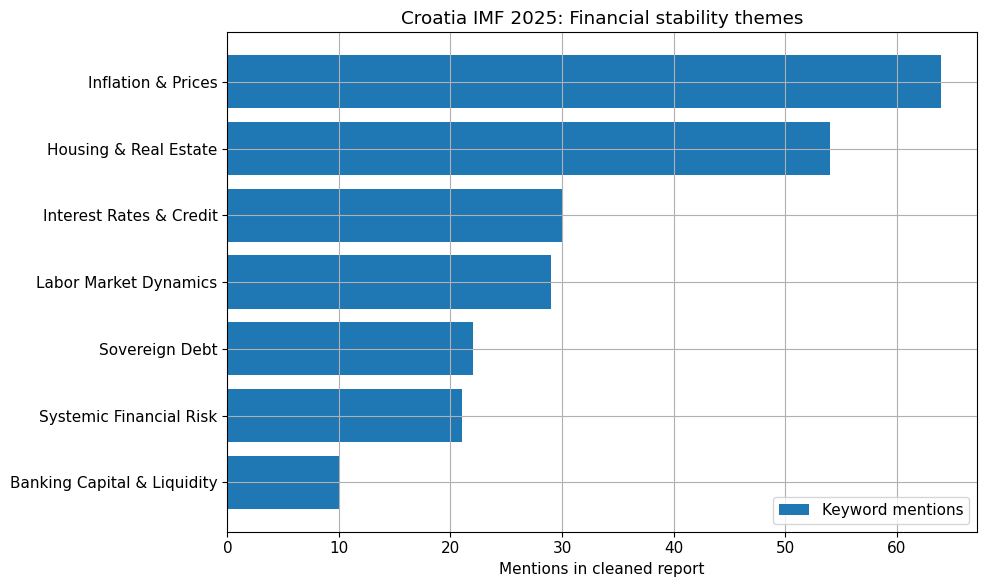

In [64]:
# Plot 1: all seven themes

fig, ax = plt.subplots()

order = sorted(theme_counts, key=theme_counts.get)

ax.barh(
    order,
    [theme_counts[x] for x in order],
    label='Keyword mentions'
)

ax.set_xlabel('Mentions in cleaned report')
ax.set_title('Croatia IMF 2025: Financial stability themes')
ax.legend()

finish('01_themes.png')

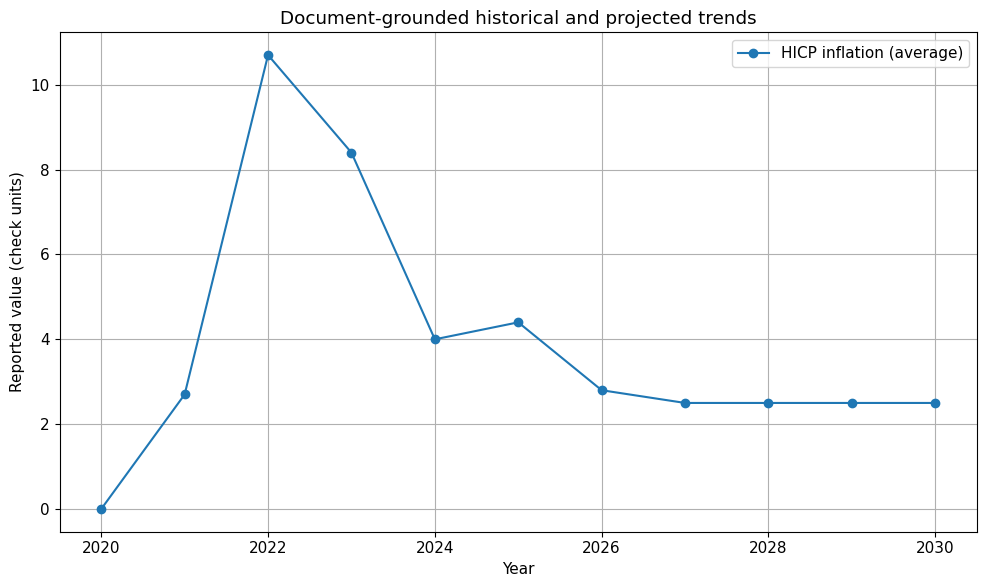

In [65]:
# Plot 2: temporal series — only if valid data exist

fig, ax = plt.subplots()

if len(trend_df) and {'year', 'indicator', 'value'}.issubset(trend_df.columns):
    for name, grp in trend_df.groupby('indicator'):
        if len(grp) >= 2:
            ax.plot(
                grp['year'],
                grp['value'],
                marker='o',
                label=name
            )

ax.set_title('Document-grounded historical and projected trends')
ax.set_xlabel('Year')
ax.set_ylabel('Reported value (check units)')

if ax.lines:
    ax.legend()
else:
    ax.text(
        .5, .5,
        'Insufficient verified time-series data',
        ha='center',
        transform=ax.transAxes
    )

finish('02_trends.png')

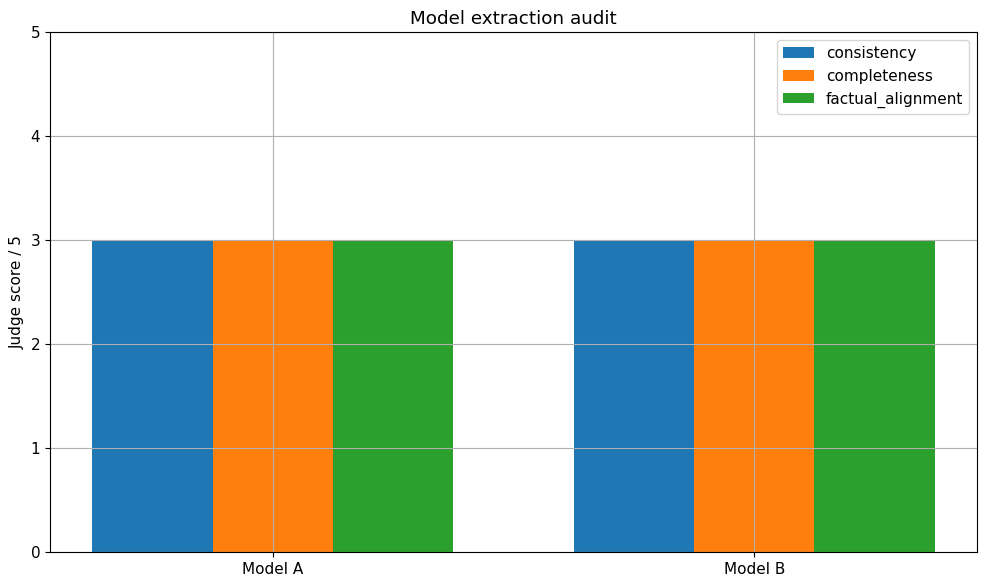

In [66]:
# Plot 3: LLM judge comparison

fig, ax = plt.subplots()

x = np.arange(2)
w = .25

for j, metric in enumerate(['consistency', 'completeness', 'factual_alignment']):
    ax.bar(
        x + (j - 1) * w,
        [audits[m].get(metric, np.nan) for m in ['A', 'B']],
        width=w,
        label=metric
    )

ax.set_xticks(x, ['Model A', 'Model B'])
ax.set_ylim(0, 5)
ax.set_ylabel('Judge score / 5')
ax.set_title('Model extraction audit')
ax.legend()

finish('03_model_comparison.png')

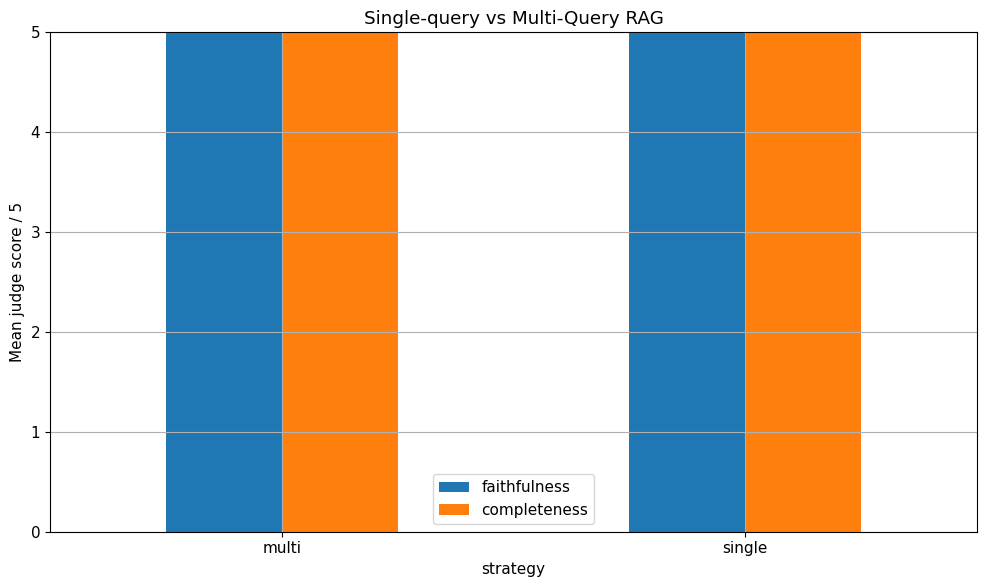

Saved four high-resolution figures (320 dpi).


In [67]:
# Plot 4: retrieval strategies (judge-based diagnostics)

fig, ax = plt.subplots()

rdf = pd.DataFrame([
    {
        'strategy': r['strategy'],
        'faithfulness': r['judge'].get('factual_alignment', np.nan),
        'completeness': r['judge'].get('completeness', np.nan)
    }
    for r in rag_results
])

means = rdf.groupby('strategy')[
    ['faithfulness', 'completeness']
].mean()

means.plot(
    kind='bar',
    ax=ax
)

ax.set_ylim(0, 5)
ax.set_ylabel('Mean judge score / 5')
ax.set_title('Single-query vs Multi-Query RAG')
ax.set_xticklabels(means.index, rotation=0)

finish('04_rag_benchmark.png')

print('Saved four high-resolution figures (320 dpi).')